# Eksplorasi Data Norton
Tahap 1: audit deskriptif atas log retail, cobrandgen, dan katalog paket. Satuan analisis adalah baris log. Seluruh hasil yang ditampilkan merupakan agregat tanpa identifier asli atau kredensial. Notebook ini tidak melatih model, mengimputasi, menghapus outlier, atau melakukan deduplikasi.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

candidates = [Path.cwd(), Path.cwd() / 'kecerdasan-bisnis', *Path.cwd().parents]
ROOT = next(path for path in candidates if (path / 'configs/audit.json').exists())
sys.path.insert(0, str(ROOT))
from src.audit import run_audit

validation = run_audit(ROOT / 'configs/audit.json')
TABLES = Path(validation['output_dir']) / 'tables'
FIGURES = Path(validation['output_dir']) / 'figures'
print({key: value for key, value in validation.items() if key != 'output_dir'})

{'total_log_rows': 14261, 'raw_inputs_unchanged': True, 'timestamp_parse_failures_nonmissing': 0, 'status_count_reconciles': True, 'price_count_reconciles': True, 'daily_count_reconciles': True, 'versions': {'python': '3.12.14', 'pandas': '3.1.0', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Inventaris dan kualitas data
Database operasional dan dokumentasi terdahulu tidak ditemukan pada workspace awal. Tipe sumber CSV dibaca sebagai teks; tipe inferensi tidak menjadikan identifier sebagai fitur numerik. Missing values ditampilkan tanpa mengisi nilai pengganti.

In [2]:
sources = pd.read_csv(TABLES / 'source_summary.csv')
profile = pd.read_csv(TABLES / 'column_profile.csv')
display(sources)
display(profile.loc[profile.missing_count.gt(0), ['source', 'column', 'missing_count', 'missing_pct']])
assert sources.loc[sources.source.ne('package'), 'rows'].sum() == validation['total_log_rows']

,source,rows,columns,exact_duplicate_excess,duplicate_excess_without_row_keys
0,retail,178,23,0,0
1,cobrandgen,14083,28,0,0
2,package,90,16,0,0


,source,column,missing_count,missing_pct
3,retail,deleted_at,178,100.0000
8,retail,callback_url,10,5.6180
10,retail,psn,10,5.6180
15,retail,subscription_start_date,10,5.6180
16,retail,subscription_cancel_date,26,14.6067
17,retail,email,178,100.0000
18,retail,referral_code,173,97.1910
19,retail,sec_ch,178,100.0000
20,retail,user_agent,151,84.8315
21,retail,device_data,156,87.6404


## Nilai tercatat dan komposisi kanal
Jumlah price adalah total nilai kolom log, bukan pendapatan bersih. Mata uang dan rekonsiliasi pembayaran belum tersedia. Histogram memakai ln(1+price) dan tetap mencakup harga nol. Ketimpangan ukuran kanal dan periode observasi membatasi perbandingan volume.

,channel,count,invalid_or_missing,min,p25,median,p75,p95,p99,max,mean,recorded_value_sum,zero_count,negative_count,above_upper_iqr_fence
0,cobrandgen,14083,0,1000,11000.0,15000.0,15000.0,15000.0,109000.0,500000,14982.3901,210997000,0,0,702
1,retail,178,0,0,15000.0,15000.0,15000.0,50000.0,500000.0,500000,24123.0337,4293900,8,0,13


Total nilai tercatat, satuan sumber: 215290900


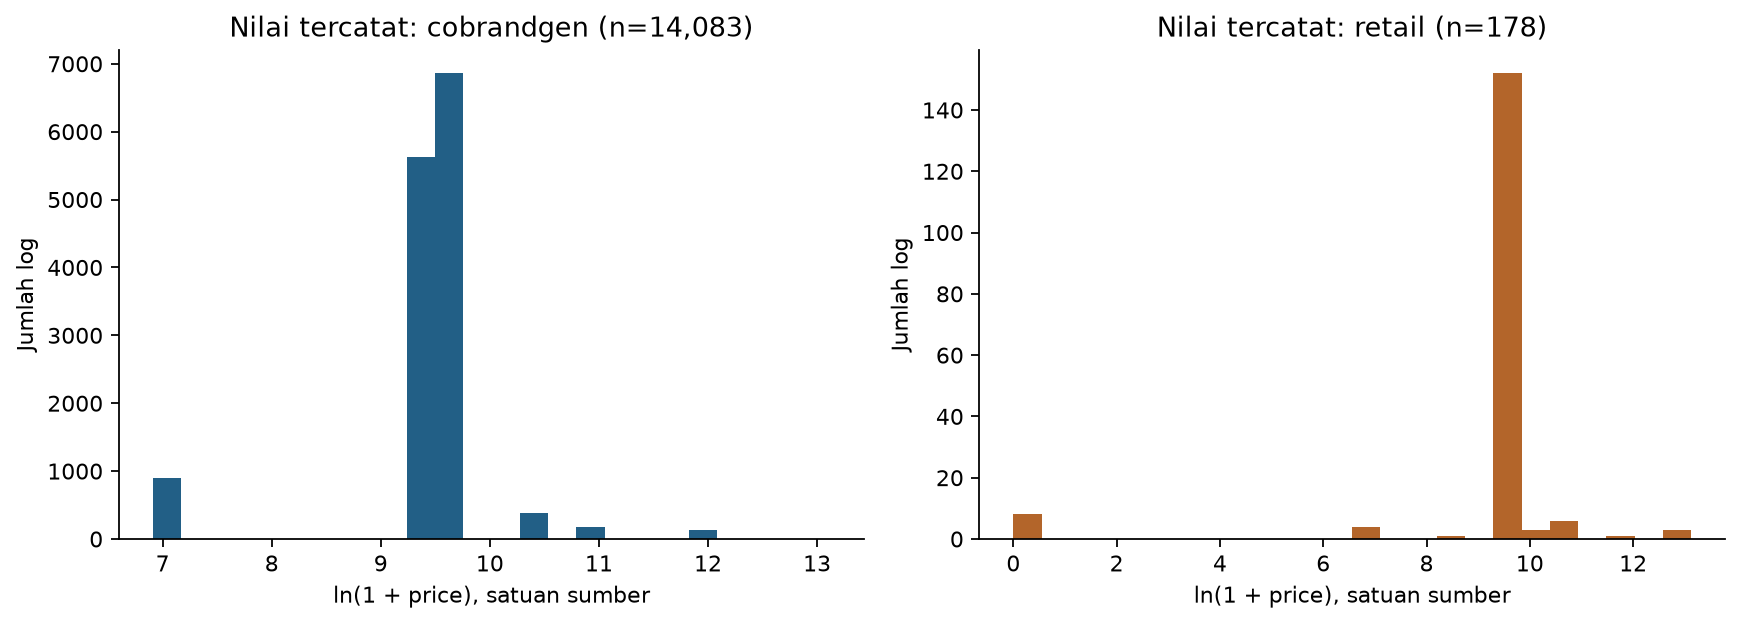

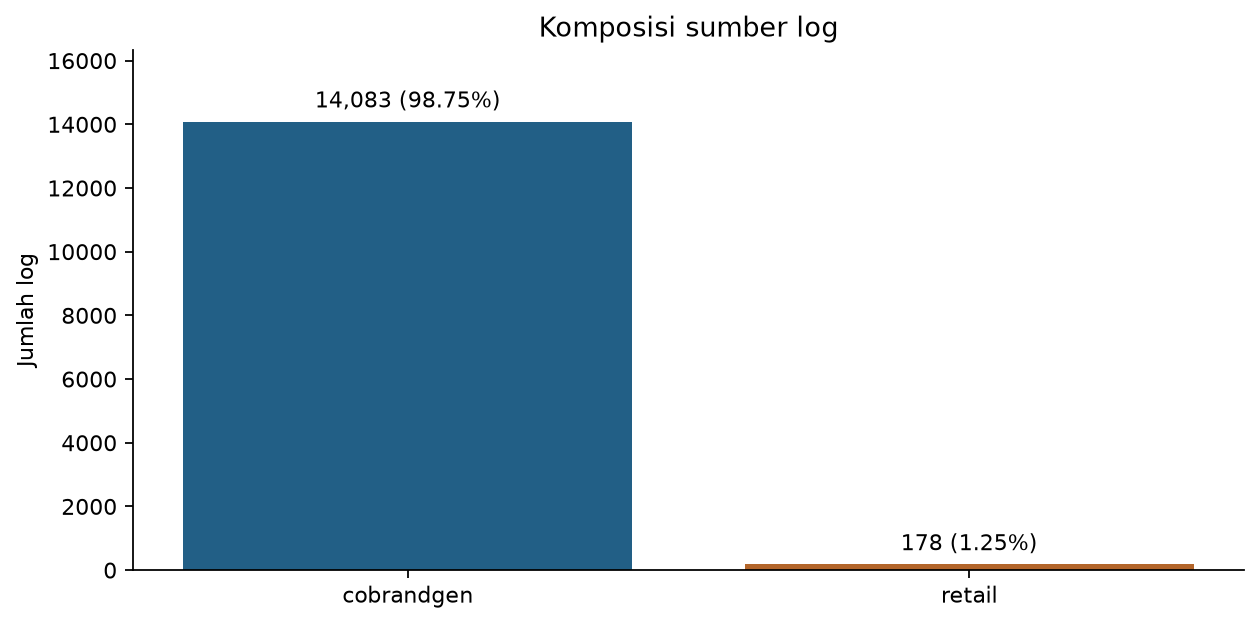

In [3]:
prices = pd.read_csv(TABLES / 'price_summary.csv')
distribution = pd.read_csv(TABLES / 'price_distribution.csv')
display(prices.round(4))
recorded_total = (distribution.amount * distribution.log_count).sum()
assert recorded_total == prices.recorded_value_sum.sum()
print('Total nilai tercatat, satuan sumber:', int(recorded_total))
display(Image(filename=str(FIGURES / '01_value_distribution.png')))
display(Image(filename=str(FIGURES / '03_channel_distribution.png')))

## Timestamp, tren, dan status
Aturan parser menghapus token literal .-1f pada salinan di memori, membaca tanggal day-first, dan mempertahankan UTC. Status adalah snapshot ekspor; ACTIVE bukan bukti pembayaran, CANCEL bukan label churn. Nol pada tren harian hanya berarti tidak ada log teramati di dalam cakupan sumber.

,source,column,missing,artifact_replacements,parse_failures_nonmissing,min_utc,max_utc
0,retail,created_at,0,178,0,2025-09-18T02:21:56+00:00,2026-08-02T00:14:57+00:00
1,retail,updated_at,0,178,0,2025-09-18T02:55:21+00:00,2026-08-07T01:00:01+00:00
2,retail,deleted_at,178,0,0,NaN,NaN
3,retail,subscription_expired_at,0,178,0,2026-01-16T02:21:56+00:00,2030-09-16T04:02:49+00:00
4,retail,subscription_start_date,10,168,0,2025-09-18T02:21:57+00:00,2026-08-02T00:14:58+00:00
5,retail,subscription_cancel_date,26,152,0,2025-09-24T08:44:43+00:00,2026-08-07T01:00:01+00:00
6,cobrandgen,created_at,0,14070,0,2026-05-11T06:34:25+00:00,2026-08-07T06:50:58+00:00
7,cobrandgen,updated_at,0,14071,0,2026-05-11T06:34:25+00:00,2026-08-07T06:50:58+00:00
8,cobrandgen,deleted_at,14083,0,0,NaN,NaN
9,cobrandgen,subscription_expired_at,0,14071,0,2026-05-12T06:34:25+00:00,2028-07-23T13:31:56+00:00


,channel,status,log_count
0,cobrandgen,ACTIVE,9270
1,cobrandgen,CANCEL,4806
2,cobrandgen,FAILED,6
3,cobrandgen,PENDING,1
4,retail,ACTIVE,16
5,retail,CANCEL,152
6,retail,PENDING,10


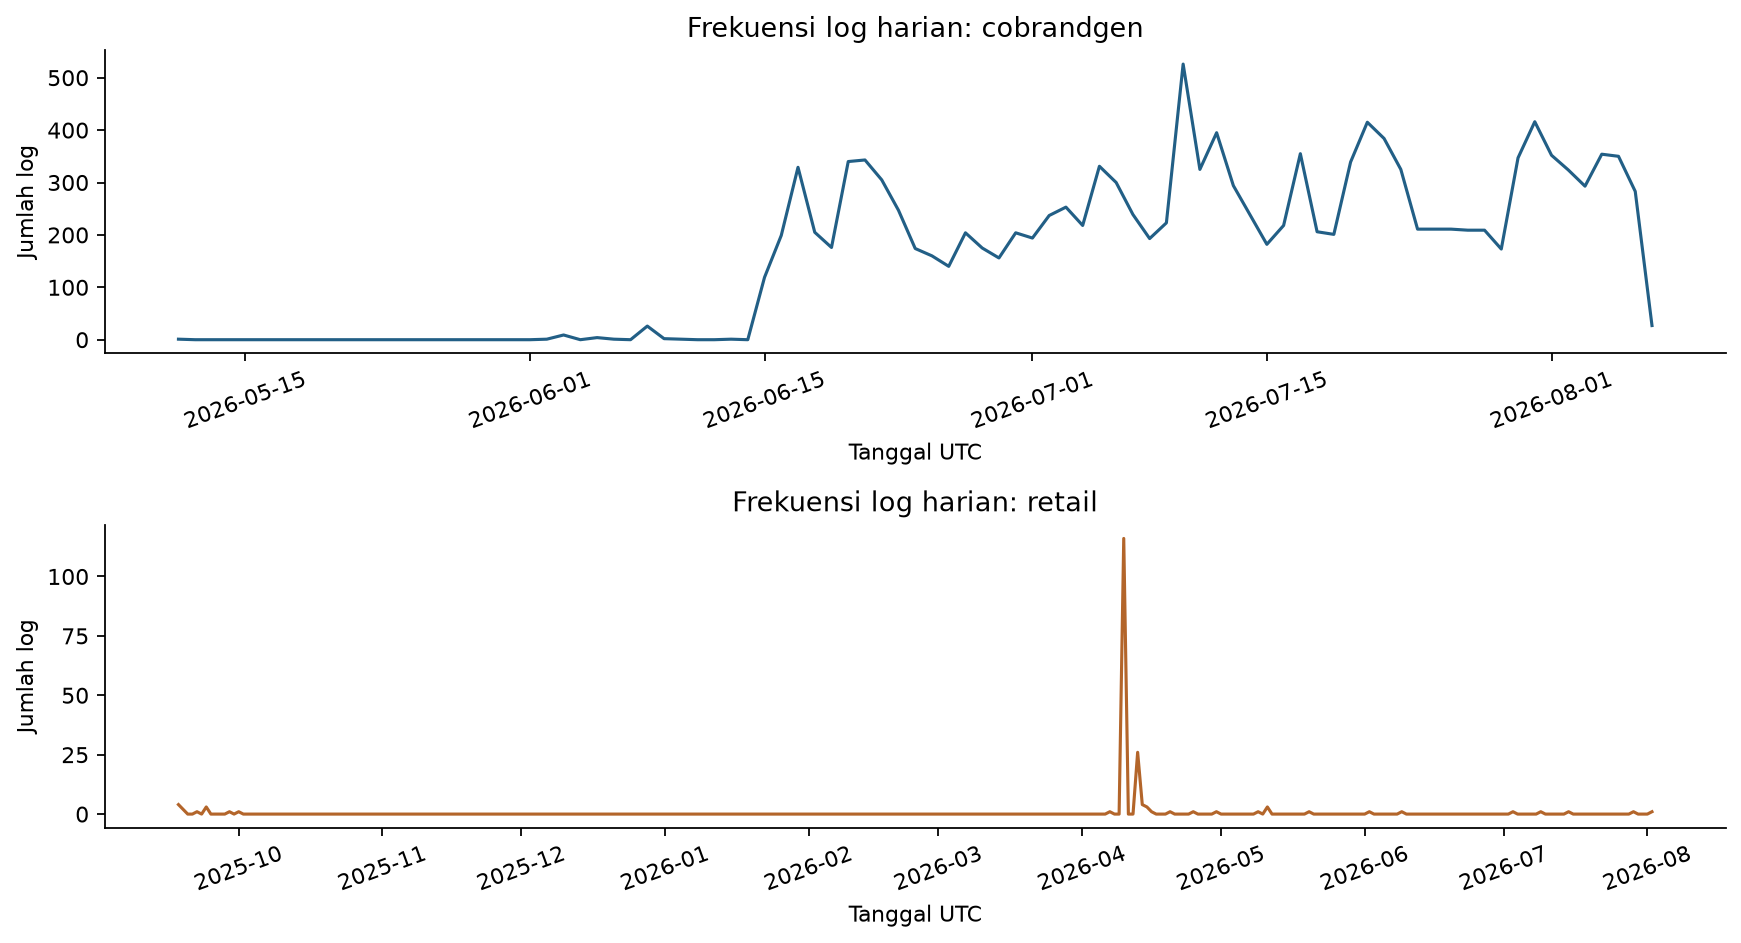

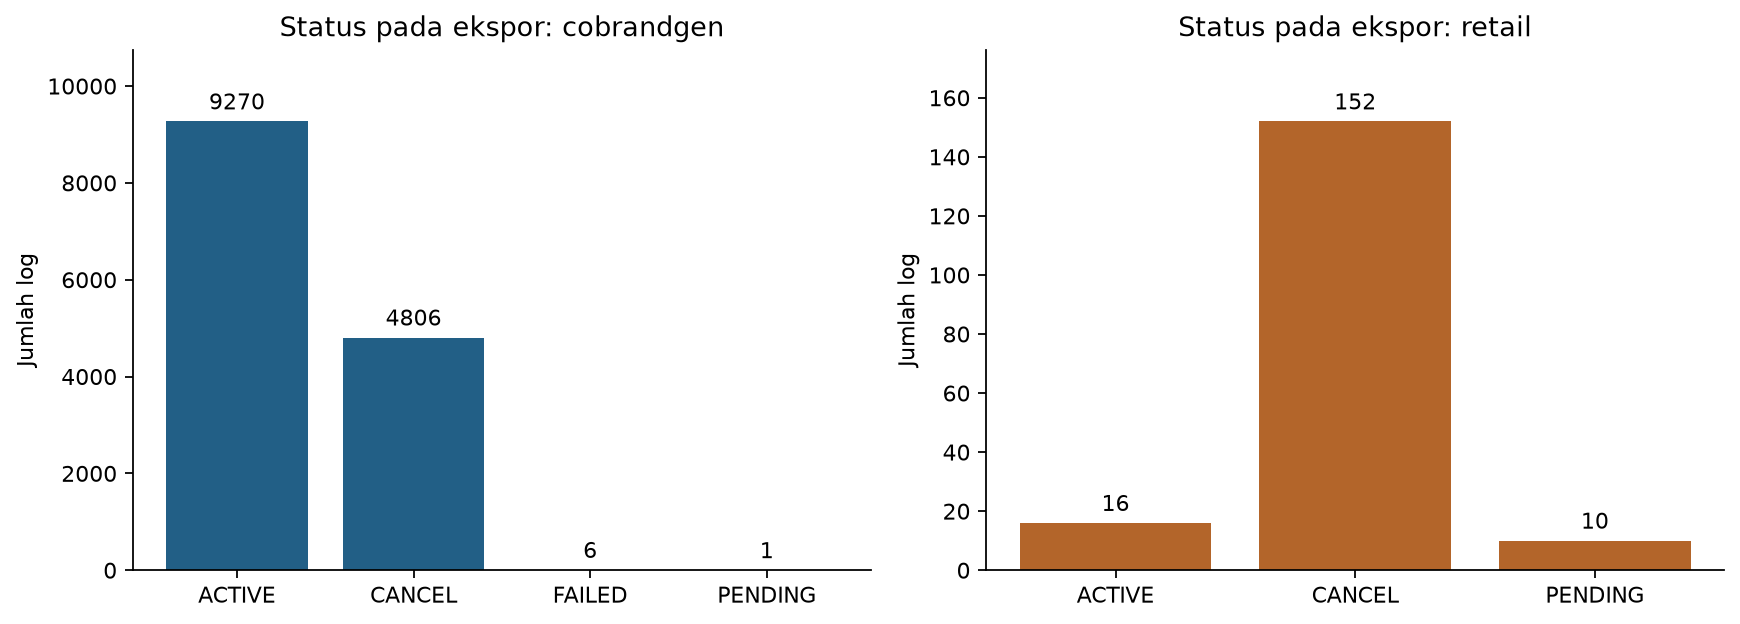

In [4]:
timestamps = pd.read_csv(TABLES / 'timestamp_quality.csv')
statuses = pd.read_csv(TABLES / 'status_counts.csv')
display(timestamps)
display(statuses)
assert timestamps.parse_failures_nonmissing.sum() == 0
assert statuses.log_count.sum() == validation['total_log_rows']
display(Image(filename=str(FIGURES / '02_daily_activity.png')))
display(Image(filename=str(FIGURES / '04_activation_status.png')))

## Riwayat akun dan pengulangan log
Grouping memakai pasangan kanal dan identifier dalam memori. Keluaran tidak menampilkan nilai identifier. Pengulangan transaction_id diperiksa sebagai rangkaian log, tanpa menyebutnya duplikat pembelian. Kelangkaan riwayat menjadi batas utama fitur akun.

,source,accounts,single_log_accounts,accounts_at_least_3_logs,accounts_at_least_5_logs,logs_without_strictly_prior_account_timestamp,same_account_timestamp_groups,rows_in_same_account_timestamp_groups,consecutive_intervals,zero_intervals,median_gap_seconds,p95_gap_seconds,max_gap_seconds
0,retail,41,34,4,3,42,13,26,137,13,69.0,10018.40,17269259.0
1,cobrandgen,9285,5182,443,37,9285,0,0,4798,0,2591880.0,2592527.15,4082575.0


,source,key,unique,repeated_groups,rows_in_repeated_groups,max_rows_per_key
0,retail,transaction_id,51,6,133,64
1,retail,customer_id,41,7,144,65
2,cobrandgen,transaction_id,9763,3808,8128,9
3,cobrandgen,customer_id,9285,4103,8901,11


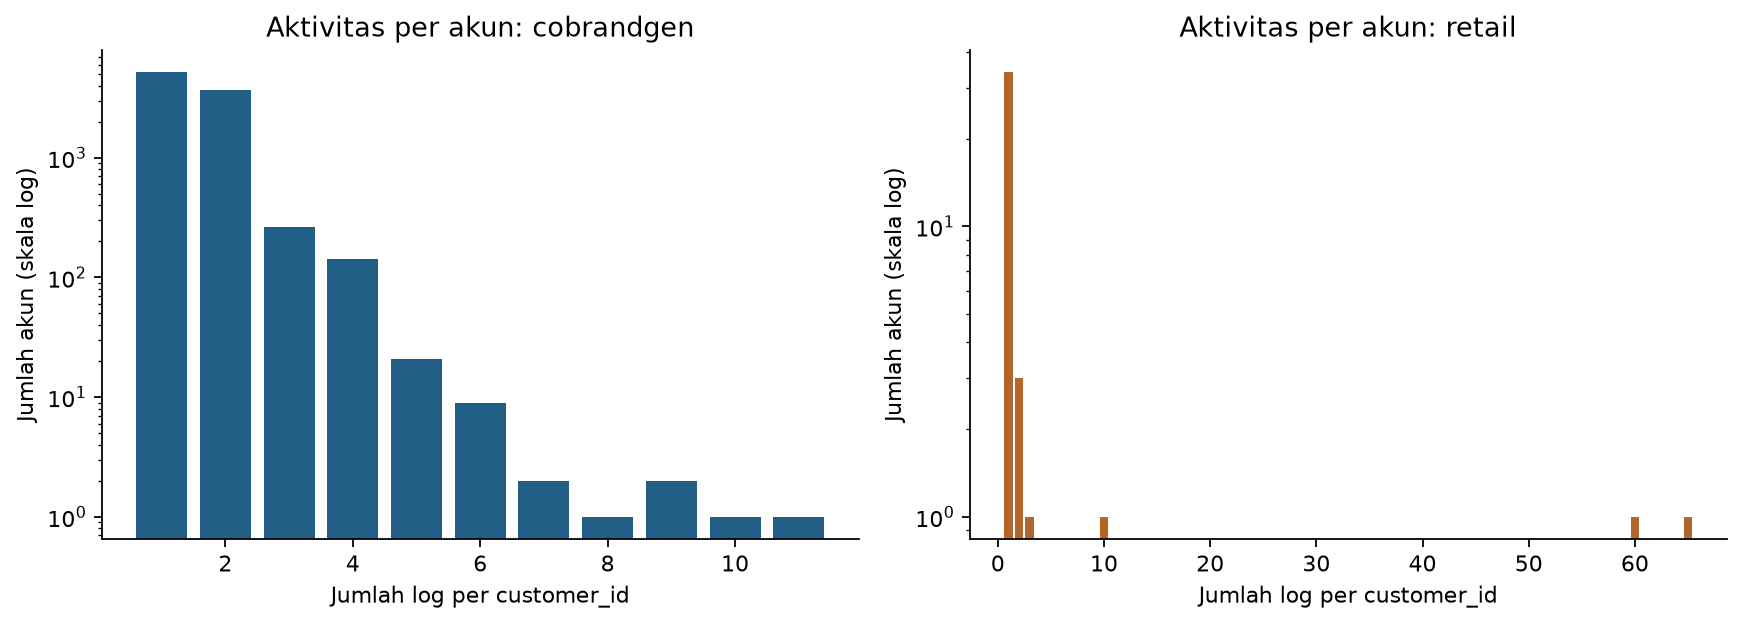

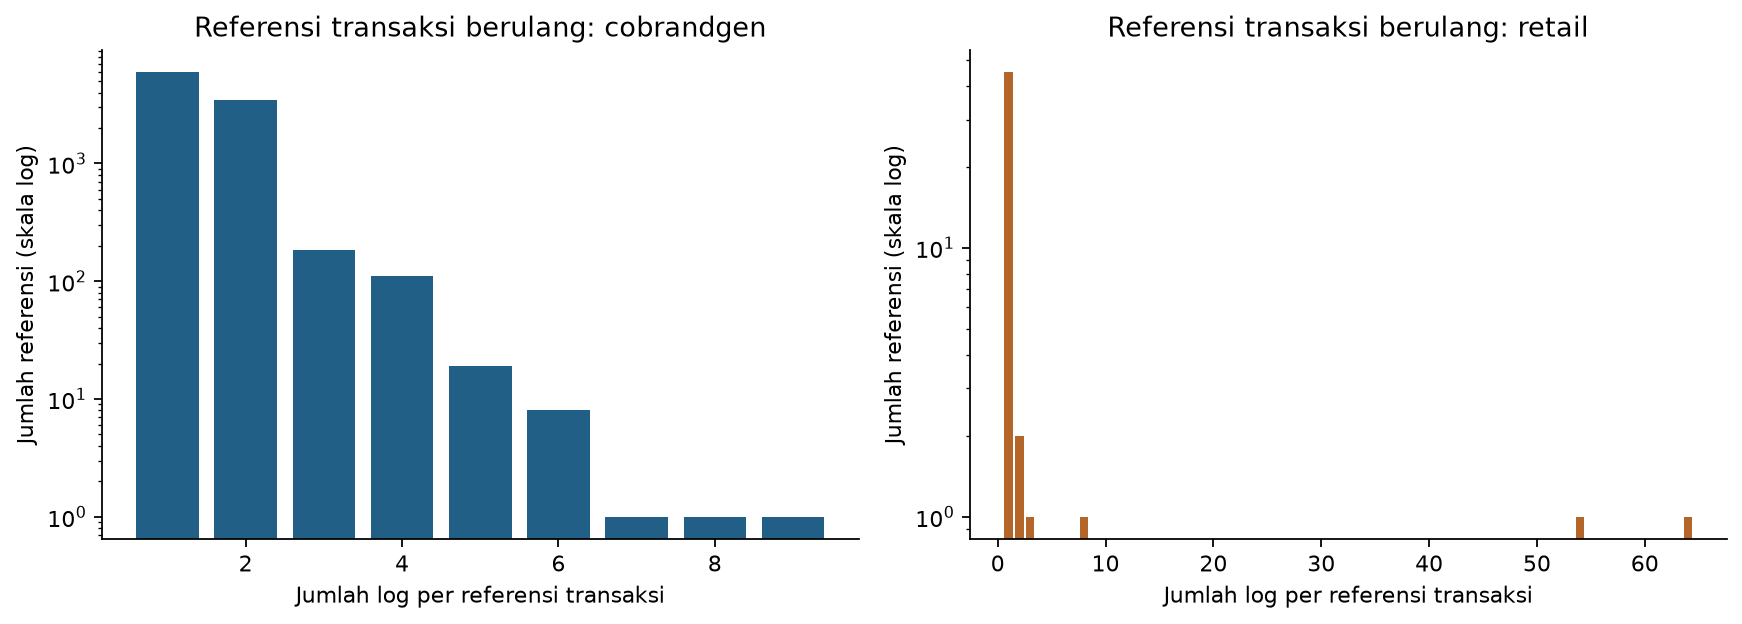

In [5]:
history = pd.read_csv(TABLES / 'account_history.csv')
repetitions = pd.read_csv(TABLES / 'repetition_summary.csv')
display(history.round(4))
display(repetitions)
display(Image(filename=str(FIGURES / '05_account_activity.png')))
display(Image(filename=str(FIGURES / '06_repeated_patterns.png')))

## Interval dan konsistensi temporal
Interval EDA dihitung dari created_at berurutan per akun-kanal setelah sort. Waktu sama menghasilkan interval nol tanpa menyatakan urutan kejadian di dalam detik tersebut. Fitur historis kelak harus memakai waktu strictly earlier untuk seluruh batch timestamp sama.

,source,check,count,eligible_rows_or_groups
0,retail,repeated_transaction_varies_status_activated,5,6
1,retail,repeated_transaction_varies_customer_id,0,6
2,retail,repeated_transaction_varies_price,0,6
3,retail,repeated_transaction_varies_pricing_id,0,6
4,retail,repeated_transaction_varies_subscription_start...,0,6
5,retail,repeated_transaction_varies_subscription_expir...,6,6
6,retail,updated_before_created,0,178
7,retail,updated_after_created,151,178
8,retail,start_before_created,127,168
9,retail,start_after_created,41,168


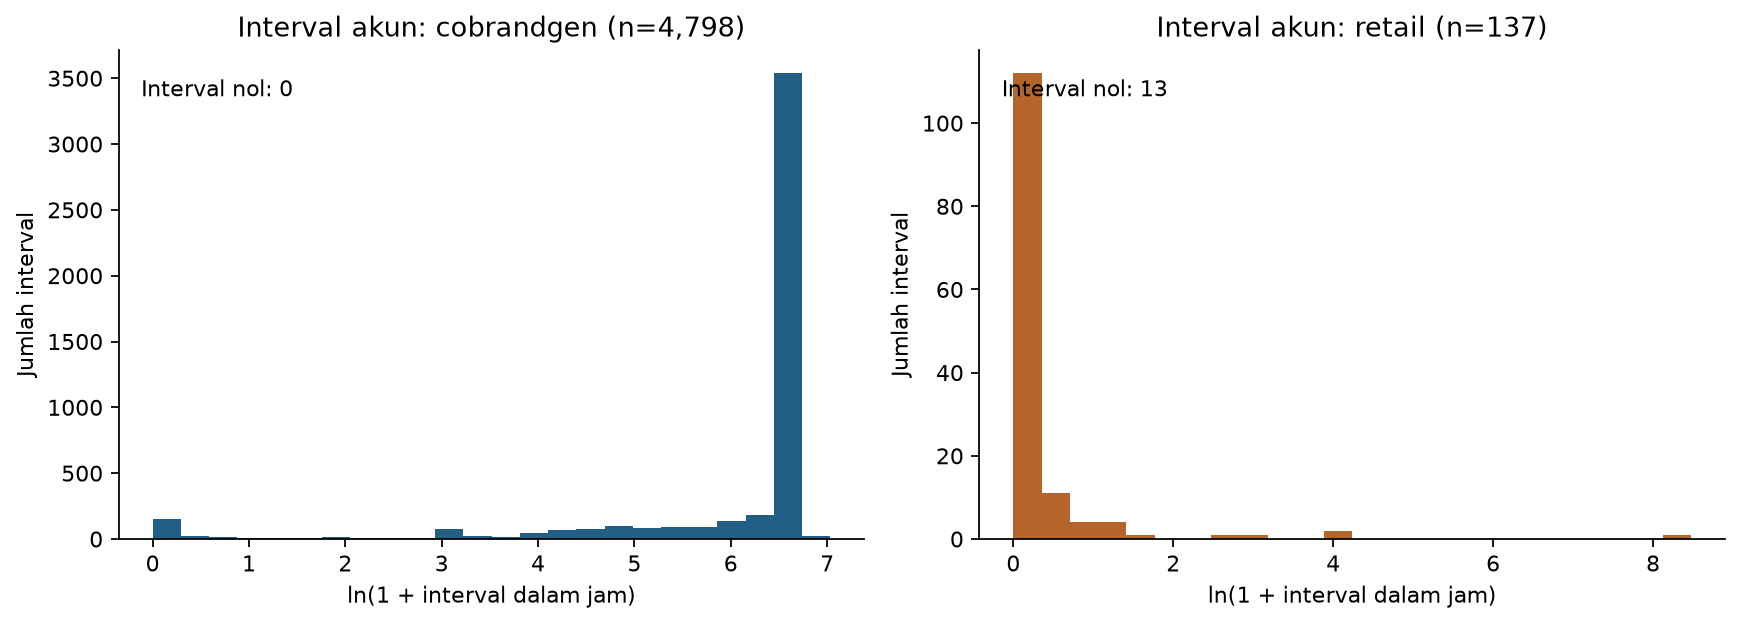

In [6]:
temporal = pd.read_csv(TABLES / 'temporal_checks.csv')
display(temporal)
display(Image(filename=str(FIGURES / '07_intertransaction_intervals.png')))

## Relasi katalog dan keputusan audit
Katalog belum digabungkan dengan log. Tidak adanya kecocokan langsung pricing_id dan kosongnya atribut nama/SKU pada log memerlukan mapping pricing yang terverifikasi. Statistik audit tidak menetapkan model terbaik atau performa deteksi anomali.

In [7]:
display(pd.read_csv(TABLES / 'catalog_join_checks.csv'))
display(pd.read_csv(TABLES / 'cross_channel_key_overlap.csv'))
print('Data mentah tetap utuh:', validation['raw_inputs_unchanged'])

,channel,log_column,package_column,nonmissing_log_rows,distinct_log_values,matched_rows_exact,target_unique_nonmissing,join_validated
0,retail,pricing_id,id,178,12,0,True,False
1,cobrandgen,pricing_id,id,14083,14,0,True,False
2,cobrandgen,package_name,name,0,0,0,False,False
3,cobrandgen,skup,spku,0,0,0,False,False


,key,distinct_value_overlap
0,customer_id,0
1,transaction_id,0
2,pricing_id,0


Data mentah tetap utuh: True


## Kelanjutan
Laporan audit berada di outputs/reports/data_audit_report.md. Implementasi fitur, tiga model, evaluasi retrospektif, alasan statistik, mart terpisah, dan dashboard dijalankan melalui run_pipeline.py. Rujuk docs/architecture_and_experiments.md serta outputs/reports/model_comparison_report.md untuk metode dan hasil aktual. Notebook ini khusus audit dan EDA.